# Justice Delayed: Court System Indicators Across India

**Python mini project: EDA, ranking, and visualization**

This notebook uses the provided `Pendency of Court Cases in India.csv` and the pandas/Matplotlib methods from the class assignments.

> **Dataset note:** This file does not contain the number of pending cases. It contains related indicators: case clearance rates, population per judge, court hall shortfall, and per-capita judiciary budget. Therefore, the analysis ranks these indicators and does not report pending-case totals.

## 1. Import libraries

We use pandas for reading and analyzing the data, and Matplotlib for charts.

In [1]:
%pip install pandas matplotlib
# Load the libraries used for tables, analysis, and charts.
import pandas as pd
import matplotlib.pyplot as plt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Load the dataset

Keep the CSV file in the same folder as this notebook. The first column in the supplied file is an extra row number, so we remove it below.

In [2]:
# Read the CSV from the notebook folder into a DataFrame.
df = pd.read_csv('Pendency of Court Cases in India.csv')

print('First five rows:')
print(df.head())

First five rows:
   Unnamed: 0                          State/UT  \
0           0                             India   
1           1  Andaman and Nicobar Islands (UT)   
2           2                    Andhra Pradesh   
3           3                 Arunachal Pradesh   
4           4                             Assam   

   Budget per capita on judiciary (₹) (2020–21)  \
0                                           146   
1                                           337   
2                                           145   
3                                           199   
4                                            99   

   Population per High Court Judge (2022)  \
0                                 1765760   
1                                 1833444   
2                                 1765733   
3                                 1681917   
4                                 1681917   

   Population per Lower Court Judge (2022) Courthall shortfall (%) (2022)  \
0                    

## 3. Explore the dataset

Check the number of rows and columns, column names, data types, and missing values.

In [3]:
# Inspect dataset size, schema, data types, and missing values.
print('Rows and columns:')
print(df.shape)

print('Column names:')
print(df.columns)

print('Dataset information:')
df.info()

print('Missing values in each column:')
print(df.isnull().sum())

Rows and columns:
(37, 8)
Column names:
Index(['Unnamed: 0', 'State/UT',
       'Budget per capita on judiciary (₹) (2020–21)',
       'Population per High Court Judge (2022)',
       'Population per Lower Court Judge (2022)',
       'Courthall shortfall (%) (2022)',
       'Case clearance rate of High Court (2022)',
       'Case clearance rate of Lower Court (2022)'],
      dtype='str')
Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 37 entries, 0 to 36
Data columns (total 8 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Unnamed: 0                                    37 non-null     int64  
 1   State/UT                                      37 non-null     str    
 2   Budget per capita on judiciary (₹) (2020–21)  37 non-null     int64  
 3   Population per High Court Judge (2022)        37 non-null     int64  
 4   Population per Lower Court Judge (2022)   

## 4. Clean and rename columns

Rename the long headings to shorter names for easier analysis. Convert the numeric columns to numbers. Some court-hall values have a percent sign or a minus sign; the minus values are retained because they can indicate a surplus rather than a shortfall.

In [4]:
# Remove an exported row-number column if it is present.
# Shorten source headings so they are easier to reference in code.
# Convert indicator columns to numeric values; unparseable entries become missing.
# Strip percent signs and spaces before converting each selected column.
df = df.drop(columns=['Unnamed: 0'], errors='ignore')

df = df.rename(columns={
    'State/UT': 'state',
    'Budget per capita on judiciary (₹) (2020–21)': 'budget_per_capita',
    'Population per High Court Judge (2022)': 'population_per_high_court_judge',
    'Population per Lower Court Judge (2022)': 'population_per_lower_court_judge',
    'Courthall shortfall (%) (2022)': 'courthall_shortfall_percent',
    'Case clearance rate of High Court (2022)': 'high_court_clearance_rate',
    'Case clearance rate of Lower Court (2022)': 'lower_court_clearance_rate'
})

number_columns = ['budget_per_capita', 'population_per_high_court_judge',
                  'population_per_lower_court_judge', 'courthall_shortfall_percent',
                  'high_court_clearance_rate', 'lower_court_clearance_rate']

for column in number_columns:
    df[column] = pd.to_numeric(
        df[column].astype(str).str.replace('%', '', regex=False).str.replace(' ', '', regex=False),
        errors='coerce'
    )

print('Cleaned column names:')
print(df.columns)
print('Missing values after cleaning:')
print(df.isnull().sum())

Cleaned column names:
Index(['state', 'budget_per_capita', 'population_per_high_court_judge',
       'population_per_lower_court_judge', 'courthall_shortfall_percent',
       'high_court_clearance_rate', 'lower_court_clearance_rate'],
      dtype='str')
Missing values after cleaning:
state                               0
budget_per_capita                   0
population_per_high_court_judge     0
population_per_lower_court_judge    0
courthall_shortfall_percent         1
high_court_clearance_rate           0
lower_court_clearance_rate          0
dtype: int64


## 5. Separate India total from state/UT rows

The file has one `India` row and individual state/UT rows. We keep the India row for overall reference, but exclude it from state/UT rankings so it is not compared with individual regions.

In [5]:
# Keep the national total for context, but rank only individual states/UTs.
india_row = df[df['state'] == 'India']
state_data = df[df['state'] != 'India'].copy()

print('Number of state/UT rows:', state_data.shape[0])
print('India overall row:')
print(india_row)

Number of state/UT rows: 36
India overall row:
   state  budget_per_capita  population_per_high_court_judge  \
0  India                146                          1765760   

   population_per_lower_court_judge  courthall_shortfall_percent  \
0                             71224                         14.7   

   high_court_clearance_rate  lower_court_clearance_rate  
0                         95                        89.0  


## 6. Summary statistics

The summary describes the state/UT rows. Population per judge is an indicator of how many people share each judge; it is not a direct measure of the number of pending cases.

In [6]:
# Summarize the selected indicators across state/UT rows.
print('Summary statistics for state/UT data:')
print(state_data[number_columns].describe().round(2))

Summary statistics for state/UT data:
       budget_per_capita  population_per_high_court_judge  \
count              36.00                            36.00   
mean              222.33                       1582332.83   
std               140.66                        719224.84   
min                50.00                        227667.00   
25%               136.50                        964892.00   
50%               188.50                       1663673.00   
75%               272.00                       1941636.00   
max               635.00                       3674088.00   

       population_per_lower_court_judge  courthall_shortfall_percent  \
count                             36.00                        35.00   
mean                           66920.03                        14.73   
std                            34256.52                        18.41   
min                            29927.00                       -38.50   
25%                            42034.75             

## 7. Rank by lower court case clearance rate

A clearance rate is the number of cases disposed compared with cases received during a period. A value around 100% means disposals and new cases are about equal; below 100% may indicate that pending cases are growing, while above 100% may indicate reduction. It does not tell us how long a case waited.

In [7]:
# Select, omit missing rates, then sort from highest to lowest.
lower_court_ranking = state_data[['state', 'lower_court_clearance_rate']]
lower_court_ranking = lower_court_ranking.dropna().sort_values(
    by='lower_court_clearance_rate', ascending=False
)

print('State/UT ranking by lower court clearance rate:')
print(lower_court_ranking.to_string(index=False))

State/UT ranking by lower court clearance rate:
                                        state  lower_court_clearance_rate
                                      Gujarat                  117.000000
                              Puducherry (UT)                  114.000000
                                          Goa                  113.000000
                                       Kerala                  113.000000
                                      Mizoram                  111.000000
                                      Tripura                  104.000000
                                    Meghalaya                  103.000000
                                      Manipur                  103.000000
                                       Punjab                  100.000000
                                   Tamil Nadu                   98.000000
                                       Sikkim                   97.000000
Dadra and Nagar Haveli and Daman and Diu (UT)                   

## 8. Bar chart: lower court clearance rate

This chart shows the 10 highest and 10 lowest state/UT clearance rates from the dataset.

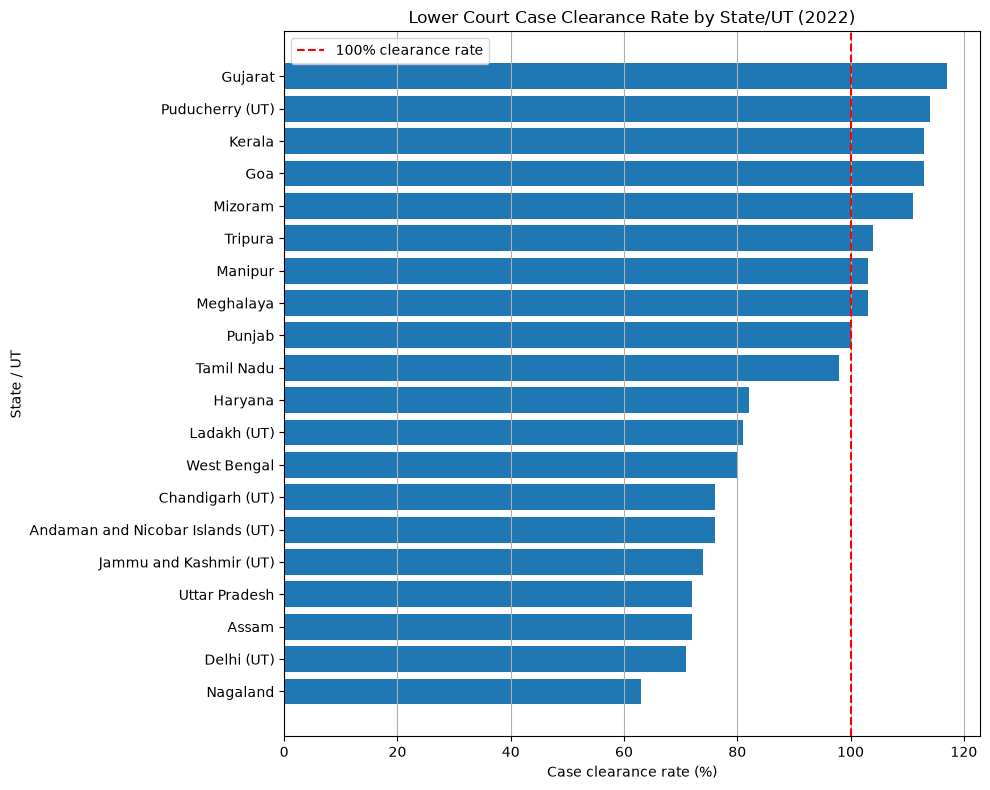

In [8]:
# Combine the 10 lowest and 10 highest rates for a compact comparison.
# Draw horizontal bars and mark the 100% balance point.
lowest_10 = lower_court_ranking.tail(10)
highest_10 = lower_court_ranking.head(10)
chart_data = pd.concat([lowest_10, highest_10]).drop_duplicates().sort_values('lower_court_clearance_rate')

plt.figure(figsize=(10, 8))
plt.barh(chart_data['state'], chart_data['lower_court_clearance_rate'])
plt.axvline(100, color='red', linestyle='--', label='100% clearance rate')
plt.title('Lower Court Case Clearance Rate by State/UT (2022)')
plt.xlabel('Case clearance rate (%)')
plt.ylabel('State / UT')
plt.legend()
plt.grid(axis='x')
plt.tight_layout()
plt.show()

## 9. Compare High Court and Lower Court clearance rates

Compare the two clearance-rate columns for each state/UT. Missing values are skipped in the chart.

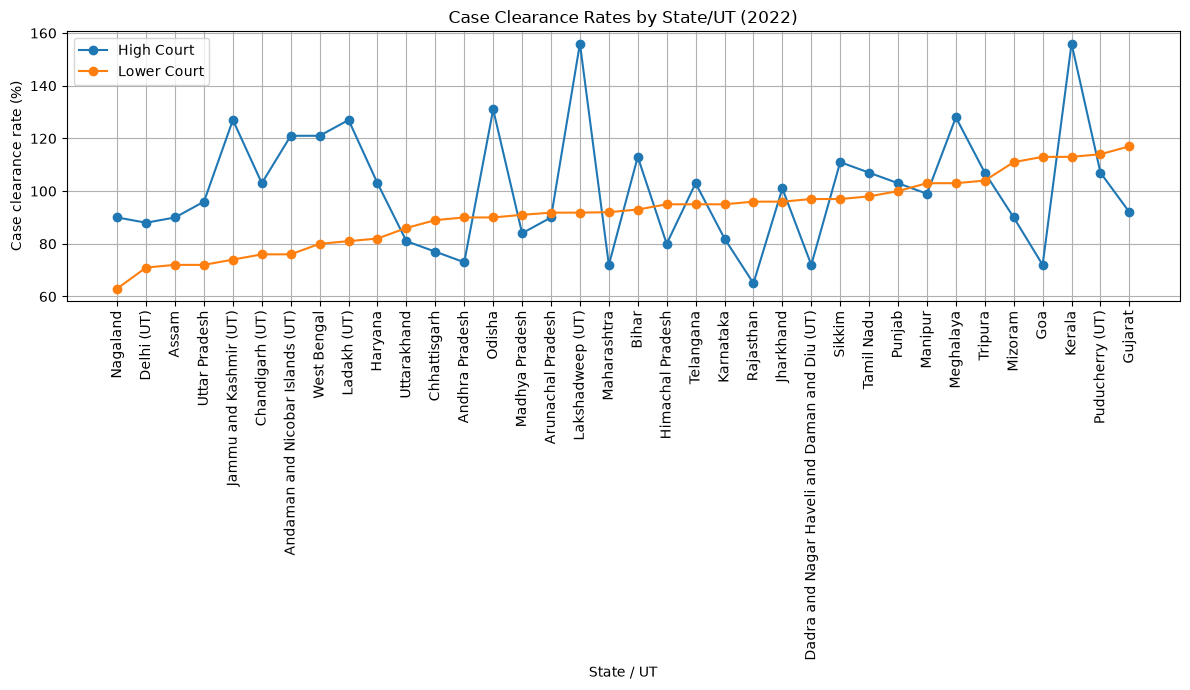

In [9]:
# Keep rows with both rates so the two court levels can be compared fairly.
# Order states by the lower-court rate to make the plot easier to scan.
clearance_data = state_data[['state', 'high_court_clearance_rate', 'lower_court_clearance_rate']].dropna()
clearance_data = clearance_data.sort_values('lower_court_clearance_rate')

plt.figure(figsize=(12, 7))
plt.plot(clearance_data['state'], clearance_data['high_court_clearance_rate'], marker='o', label='High Court')
plt.plot(clearance_data['state'], clearance_data['lower_court_clearance_rate'], marker='o', label='Lower Court')
plt.title('Case Clearance Rates by State/UT (2022)')
plt.xlabel('State / UT')
plt.ylabel('Case clearance rate (%)')
plt.xticks(rotation=90)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 10. Rank population per lower court judge

A higher population-per-judge value means more people per lower-court judge in the supplied data. It may help discuss workload context, but it does not show each judge's actual caseload.

Highest population per lower court judge:
                                        state  population_per_lower_court_judge
Dadra and Nagar Haveli and Daman and Diu (UT)                            195000
                              Puducherry (UT)                            146182
                               Andhra Pradesh                            109673
                                  West Bengal                            107412
                                Uttar Pradesh                             93021
                                        Bihar                             92259
                                    Telangana                             92231
                                     Nagaland                             92208
                                        Assam                             82274
                                      Manipur                             76048


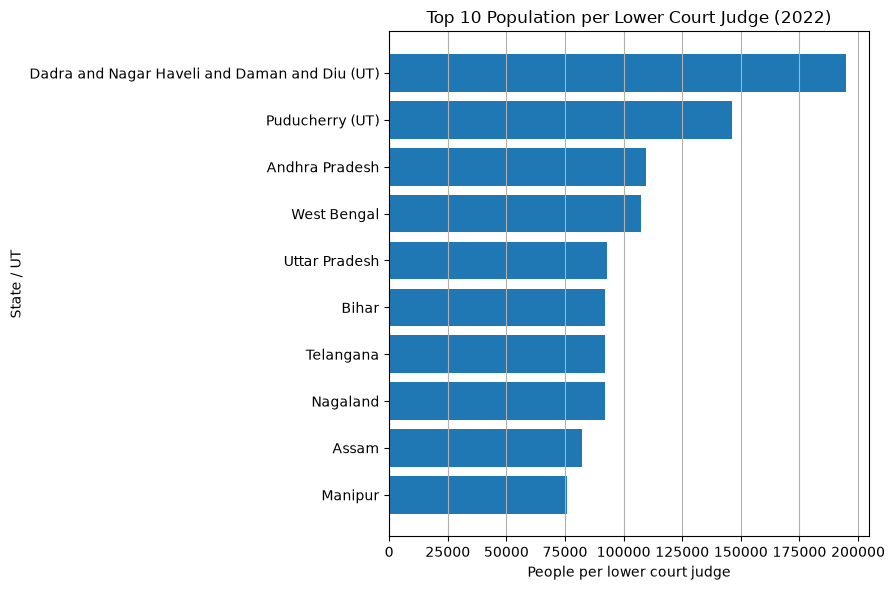

In [10]:
# Sort regions by the number of people per lower-court judge.
# Display the top 10 as a horizontal bar chart.
judge_ranking = state_data[['state', 'population_per_lower_court_judge']].dropna()
judge_ranking = judge_ranking.sort_values('population_per_lower_court_judge', ascending=False)
print('Highest population per lower court judge:')
print(judge_ranking.head(10).to_string(index=False))

chart_judges = judge_ranking.head(10).sort_values('population_per_lower_court_judge')
plt.figure(figsize=(9, 6))
plt.barh(chart_judges['state'], chart_judges['population_per_lower_court_judge'])
plt.title('Top 10 Population per Lower Court Judge (2022)')
plt.xlabel('People per lower court judge')
plt.ylabel('State / UT')
plt.grid(axis='x')
plt.tight_layout()
plt.show()

## 11. Explore court hall shortfall

Negative values are kept as recorded and may represent a surplus. This chart shows the 10 largest reported shortfalls.

                 state  courthall_shortfall_percent
           Ladakh (UT)                         47.1
             Meghalaya                         46.5
Jammu and Kashmir (UT)                         38.2
     Arunachal Pradesh                         36.6
               Mizoram                         35.4
               Manipur                         33.9
               Tripura                         32.8
            Delhi (UT)                         32.5
                Sikkim                         28.6
               Haryana                         27.7


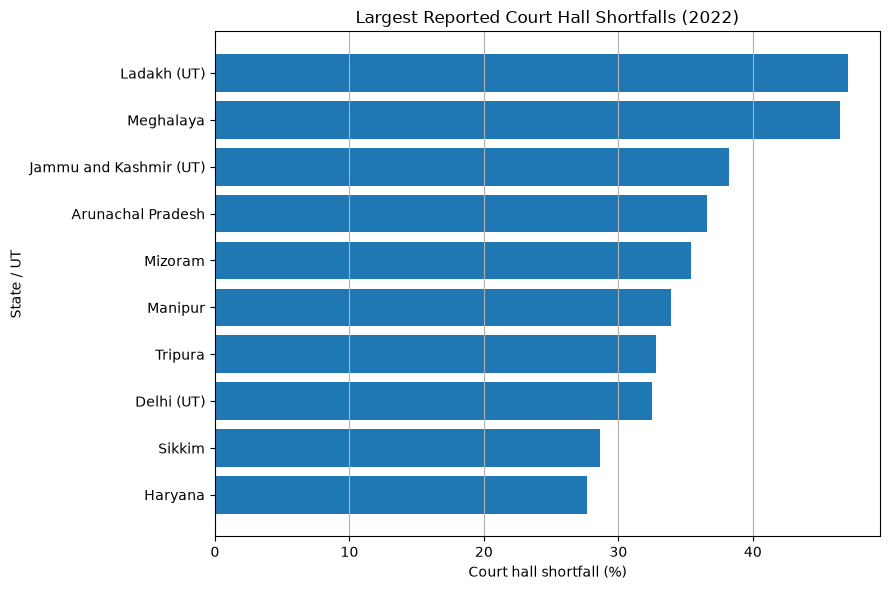

In [11]:
# Select the 10 largest recorded shortfall percentages.
# Reverse plotting order so the largest value appears at the top.
court_hall_data = state_data[['state', 'courthall_shortfall_percent']].dropna()
court_hall_data = court_hall_data.sort_values('courthall_shortfall_percent', ascending=False).head(10)
print(court_hall_data.to_string(index=False))

plt.figure(figsize=(9, 6))
plt.barh(court_hall_data['state'][::-1], court_hall_data['courthall_shortfall_percent'][::-1])
plt.title('Largest Reported Court Hall Shortfalls (2022)')
plt.xlabel('Court hall shortfall (%)')
plt.ylabel('State / UT')
plt.grid(axis='x')
plt.tight_layout()
plt.show()

## 12. Save the rankings

Save the lower court clearance and judge-population rankings as CSV files in the same folder as the notebook.

In [12]:
# Export both rankings without adding a redundant DataFrame index column.
lower_court_ranking.to_csv('lower_court_clearance_ranking.csv', index=False)
judge_ranking.to_csv('population_per_lower_court_judge_ranking.csv', index=False)
print('Ranking files saved successfully.')

Ranking files saved successfully.


## 13. Conclusion

After running the notebook, the main observations from the supplied data (2022 indicators) are:

**1. Which state/UT has the highest and lowest lower-court clearance rate?**
Gujarat has the highest lower-court clearance rate (117%), followed by Puducherry (114%), Goa and Kerala (113% each). Nagaland has the lowest (63%), followed by Delhi (71%) and Assam and Uttar Pradesh (72% each). The national average is 89%. A rate above 100% means more cases were disposed of than were filed in that year.

**2. Which state/UT has the highest population per lower-court judge?**
Dadra and Nagar Haveli and Daman and Diu has the highest population per lower-court judge (about 195,000), followed by Puducherry (146,182), Andhra Pradesh (109,673) and West Bengal (107,412). Among larger states, Andhra Pradesh and West Bengal carry the heaviest load per judge. Mizoram has the lowest (about 29,927). The national figure is 71,224.

**3. What do the court hall shortfall values show?**
Ladakh (47.1%), Meghalaya (46.5%), Jammu and Kashmir (38.2%) and Arunachal Pradesh (36.6%) have the largest shortfalls, compared with a national figure of 14.7%. Puducherry (-38.5%), Dadra and Nagar Haveli and Daman and Diu (-14.3%), Maharashtra (-7.3%) and Goa (-6.0%) have negative values, which indicate a surplus of court halls rather than a shortage. Overall, shortfalls are largest in the northeastern states and in smaller or northern UTs.

**4. What limitations should be considered?**
- The CSV contains indicators only. It does not include pending-case totals or case waiting times, so it cannot measure how long cases are delayed.
- The measures come from different years (budget for 2020–21, other indicators for 2022).
- Some values appear to be filled-in or missing: Arunachal Pradesh and Lakshadweep share the same clearance rate (91.83%), and Andaman and Nicobar Islands has no court hall shortfall value.
- Small states and UTs with few courts can show extreme values.

**Additional observation:** A high population per judge does not always mean a low clearance rate. Andhra Pradesh and Bihar have heavy workloads per judge but clear 90% and 93% of cases, while Delhi has few people per judge but clears only 71%.

**Limitation:** The provided CSV contains indicators, not pending-case totals or case waiting times. It also reports measures from different years. The results describe only the supplied data and do not prove that one factor causes another.